# DataSalud Perú – Procesamiento Big Data con PySpark vs. SQL Server
**Proyecto:** Sistema integrado de base de datos segura, automatizada e inteligente para la DIRESA La Libertad (UPN 2026_2)
**Datasets SIS/MINSA:** (1) Afiliados activos con Diabetes Mellitus – 850 366 registros, 24 campos; (2) Consumo de medicamentos en recién nacidos – 290 469 prestaciones, 374 083 diagnósticos, 931 763 medicamentos.

**Objetos Spark usados:** RDD (sección 4), DataFrame (secciones 3, 5, 6) y SparkSQL (sección 5).
**Comparación:** las mismas consultas se ejecutan en SQL Server con `01_sqlserver_comparacion.sql`; los tiempos se pegan en la sección 7.

> Antes de ejecutar: sube a Colab (panel de archivos, carpeta `/content`) los archivos del dataset. Se recomienda **CSV** (exportado desde SQL Server o Excel) porque Spark no lee `.xlsx` de forma nativa; si solo tienes `.xlsx`, la sección 2 los convierte con pandas.

## 1. Entorno y sesión Spark local (Colab)

In [1]:
!pip install -q pyspark==4.0.0

import os, time, statistics, shutil, platform
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

spark = (
    SparkSession.builder
    .appName("DataSaludPeru_BigData")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "6g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

# Registro del hardware: imprescindible para interpretar los tiempos
ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
print("Spark:", spark.version)
print("Núcleos disponibles:", os.cpu_count(), "| RAM total (GB):", round(ram_gb, 1))
print("Plataforma:", platform.platform())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.1/434.1 MB 1.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Spark: 4.0.0
Núcleos disponibles: 2 | RAM total (GB): 12.7
Plataforma: Linux-6.6.122+-x86_64-with-glibc2.39


## 2. Carga de datos
Ajusta las rutas. Si ya tienes CSV, deja `USAR_XLSX = False`.

In [2]:
USAR_XLSX = False   # True si subiste los .xlsx originales

RUTA_DM_XLSX   = "/content/Afiliados activos con DM 202512.xlsx"
RUTA_DM_CSV    = "/content/afiliados_dm.csv"
RUTA_PREST_CSV = "/content/prestaciones.csv"
RUTA_DIAG_CSV  = "/content/diagnosticos.csv"
RUTA_MED_CSV   = "/content/medicamentos.csv"

if USAR_XLSX:
    # Lectura lenta (minutos) pero se hace una sola vez; luego se trabaja con CSV/Parquet
    t0 = time.perf_counter()
    pdf = pd.read_excel(RUTA_DM_XLSX, engine="openpyxl")
    pdf.to_csv(RUTA_DM_CSV, index=False)
    print(f"xlsx -> csv: {time.perf_counter()-t0:.1f} s | filas: {len(pdf):,}")
    del pdf
    # Repite el mismo patrón para los 3 archivos del dataset de recién nacidos

In [5]:

import pandas as pd
import os
import time

archivos = {
    "Afiliados activos con DM 202512.xlsx": "afiliados_dm.csv",
    "1 Prestaciones.xlsx": "prestaciones.csv",
    "2 Diagnósticos.xlsx": "diagnosticos.csv",
    "3 Medicamentos.xlsx": "medicamentos.csv"
}

for origen, destino in archivos.items():
    inicio = time.perf_counter()

    ruta_origen = "/content/" + origen
    ruta_destino = "/content/" + destino

    print(f"Convirtiendo: {origen}")

    df = pd.read_excel(ruta_origen, engine="openpyxl")
    df.to_csv(ruta_destino, index=False, encoding="utf-8")

    print(f"Registros: {len(df):,}")
    print(f"Archivo creado: {destino}")
    print(f"Tiempo: {time.perf_counter() - inicio:.2f} segundos\n")

    del df

print("¡Conversión finalizada!")


Convirtiendo: Afiliados activos con DM 202512.xlsx
Registros: 850,366
Archivo creado: afiliados_dm.csv
Tiempo: 198.49 segundos

Convirtiendo: 1 Prestaciones.xlsx
Registros: 290,469
Archivo creado: prestaciones.csv
Tiempo: 57.96 segundos

Convirtiendo: 2 Diagnósticos.xlsx
Registros: 374,083
Archivo creado: diagnosticos.csv
Tiempo: 22.20 segundos

Convirtiendo: 3 Medicamentos.xlsx
Registros: 931,763
Archivo creado: medicamentos.csv
Tiempo: 76.12 segundos

¡Conversión finalizada!


In [6]:
import unicodedata, re

def normalizar(nombre):
    n = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Za-z0-9]+", "_", n).strip("_").upper()

def leer_csv(ruta):
    df = spark.read.option("header", True).option("inferSchema", True).csv(ruta)
    return df.toDF(*[normalizar(c) for c in df.columns])

df_dm = leer_csv(RUTA_DM_CSV)
print("Filas DM:", df_dm.count(), "| columnas:", len(df_dm.columns))
df_dm.printSchema()

Filas DM: 850366 | columnas: 19
root
 |-- FECHA_CORTE: date (nullable = true)
 |-- FECHA_AFILIADOS_SIS: date (nullable = true)
 |-- CODIGO_ANONIMIZADO: string (nullable = true)
 |-- EDAD: integer (nullable = true)
 |-- UBIGEO: integer (nullable = true)
 |-- DEPARTAMENTO: string (nullable = true)
 |-- PROVINCIA: string (nullable = true)
 |-- DISTRITO: string (nullable = true)
 |-- SEXO: string (nullable = true)
 |-- FECHA_PRIMER_DX: integer (nullable = true)
 |-- TIPO_DIABETES: string (nullable = true)
 |-- CON_DX_OBESIDAD: string (nullable = true)
 |-- CON_DX_HIPERTENSION: string (nullable = true)
 |-- CON_DX_SALUDMENTAL: string (nullable = true)
 |-- CANT_ATENCIONES: integer (nullable = true)
 |-- VALOR_NETO: double (nullable = true)
 |-- CANT_ATENCIONES_HOSP: integer (nullable = true)
 |-- VALOR_NETO_HOSP: double (nullable = true)
 |-- DIAS_HOSP: integer (nullable = true)



### 2.1 Limpieza (misma regla del Capítulo I del informe)
- Eliminar 19 registros con `VALOR_NETO`/`VALOR_NETO_HOSP` nulos.
- Excluir los 5 campos de última atención (73,59 % de nulos).

In [7]:
cols_ult = [c for c in df_dm.columns if "ULT_ATE" in c]
print("Campos de última atención excluidos:", cols_ult)

df_dm_limpio = (
    df_dm.drop(*cols_ult)
         .dropna(subset=["VALOR_NETO", "VALOR_NETO_HOSP"])
)
n_antes, n_despues = df_dm.count(), df_dm_limpio.count()
print(f"Antes: {n_antes:,} | Después: {n_despues:,} | Eliminados: {n_antes-n_despues}  (informe: 19)")

# Parquet: formato columnar, el recomendado para Spark (ver sección 6)
shutil.rmtree("/content/dm_parquet", ignore_errors=True)
df_dm_limpio.write.mode("overwrite").parquet("/content/dm_parquet")
df_dm_pq = spark.read.parquet("/content/dm_parquet")
df_dm_pq.createOrReplaceTempView("dm")

size_csv = os.path.getsize(RUTA_DM_CSV)/1024**2
size_pq  = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk("/content/dm_parquet") for f in fs)/1024**2
print(f"Tamaño CSV: {size_csv:.1f} MB | Parquet: {size_pq:.1f} MB | compresión x{size_csv/size_pq:.1f}")

Campos de última atención excluidos: []
Antes: 850,366 | Después: 850,366 | Eliminados: 0  (informe: 19)
Tamaño CSV: 156.0 MB | Parquet: 61.7 MB | compresión x2.5


In [9]:
# Dataset 2 (recién nacidos): prestaciones, diagnósticos, medicamentos
prest = leer_csv(RUTA_PREST_CSV)
diag  = leer_csv(RUTA_DIAG_CSV)
med   = leer_csv(RUTA_MED_CSV).dropna(subset=["COD_MEDICAMENTO"])   # 2 registros eliminados (informe)

for nombre, d in [("prestaciones", prest), ("diagnosticos", diag), ("medicamentos", med)]:
    print(nombre, f"{d.count():,}")
    d.createOrReplaceTempView(nombre)

prestaciones 290,469
diagnosticos 374,083
medicamentos 931,763


## 3. Marco de medición
Cada consulta se ejecuta **N veces** y se reporta la primera ejecución (*fría*: incluye planificación, JIT y lectura de disco) y la **mediana** de las siguientes (*caliente*). Se fuerza la ejecución completa con `.collect()`.

In [10]:
N_REPS = 5
tiempos_spark = {}   # {consulta: {"fria_ms":..., "mediana_ms":..., "filas":...}}

def medir(nombre, fn, reps=N_REPS):
    ms, filas = [], None
    for _ in range(reps):
        t0 = time.perf_counter()
        resultado = fn()
        ms.append((time.perf_counter() - t0) * 1000)
        filas = len(resultado)
    tiempos_spark[nombre] = {
        "fria_ms": round(ms[0], 1),
        "mediana_ms": round(statistics.median(ms[1:]), 1),
        "filas": filas,
    }
    print(f"{nombre}: fría={ms[0]:.0f} ms | mediana caliente={statistics.median(ms[1:]):.0f} ms | filas={filas}")
    return resultado

## 4. RDD – agregación clave-valor (equivalente a `reduceByKey` de la clase)

In [11]:
# Q1-RDD: valor neto total y n.º de afiliados por tipo de diabetes
def q1_rdd():
    rdd = (
        df_dm_pq.select("TIPO_DIABETES", "VALOR_NETO").rdd
        .map(lambda r: (r["TIPO_DIABETES"], (1, float(r["VALOR_NETO"]))))
        .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    )
    return rdd.collect()

res_rdd = medir("Q1 RDD (reduceByKey por tipo diabetes)", q1_rdd)
for tipo, (n, total) in sorted(res_rdd, key=lambda x: -x[1][1]):
    print(f"{str(tipo)[:45]:45s} n={n:>9,}  valor_neto_total={total:>14,.2f}")

Q1 RDD (reduceByKey por tipo diabetes): fría=9414 ms | mediana caliente=5110 ms | filas=5
Diabetes mellitus tipo 2                      n=  637,740  valor_neto_total= 29,397,036.45
Diabetes mellitus no especificada             n=  155,924  valor_neto_total=  6,604,256.50
Diabetes mellitus tipo 1                      n=   42,882  valor_neto_total=  4,765,527.14
Otras Diabetes mellitus especificada          n=   12,005  valor_neto_total=  1,136,660.84
Diabetes mellitus asociada con desnutrición   n=    1,815  valor_neto_total=    269,489.76


## 5. DataFrame y SparkSQL – estadística descriptiva y agregación
Las cuatro consultas tienen su equivalente T-SQL en `01_sqlserver_comparacion.sql` (mismos nombres Q1…Q5).

In [12]:
# Q1 – Estadística descriptiva por tipo de diabetes y sexo (DataFrame API)
def q1_df():
    return (df_dm_pq.groupBy("TIPO_DIABETES", "SEXO")
        .agg(F.count("*").alias("afiliados"),
             F.round(F.avg("EDAD"), 2).alias("edad_media"),
             F.round(F.stddev("EDAD"), 2).alias("edad_desv"),
             F.round(F.sum("VALOR_NETO"), 2).alias("valor_neto_total"),
             F.round(F.avg("VALOR_NETO"), 2).alias("valor_neto_medio"),
             F.max("DIAS_HOSP").alias("dias_hosp_max"))
        .orderBy(F.col("valor_neto_total").desc())
        .collect())
r = medir("Q1 DataFrame (descriptiva tipo x sexo)", q1_df)
pd.DataFrame([x.asDict() for x in r]).head(10)

Q1 DataFrame (descriptiva tipo x sexo): fría=4115 ms | mediana caliente=1021 ms | filas=10


,TIPO_DIABETES,SEXO,afiliados,edad_media,edad_desv,valor_neto_total,valor_neto_medio,dias_hosp_max
0,Diabetes mellitus tipo 2,FEMENINO,421535,55.93,16.49,16443634.01,39.01,899
1,Diabetes mellitus tipo 2,MASCULINO,216205,56.38,17.04,12953402.44,59.91,1827
2,Diabetes mellitus no especificada,FEMENINO,103034,53.61,17.86,3815383.88,37.03,142
3,Diabetes mellitus no especificada,MASCULINO,52890,54.09,19.04,2788872.62,52.73,1079
4,Diabetes mellitus tipo 1,FEMENINO,25964,53.62,19.34,2438150.10,93.91,1856
5,Diabetes mellitus tipo 1,MASCULINO,16918,52.51,19.99,2327377.04,137.57,179
6,Otras Diabetes mellitus especificada,FEMENINO,8032,52.19,18.45,700117.15,87.17,121
7,Otras Diabetes mellitus especificada,MASCULINO,3973,54.48,19.82,436543.69,109.88,76
8,Diabetes mellitus asociada con desnutrición,FEMENINO,1098,53.50,19.68,151172.75,137.68,59
9,Diabetes mellitus asociada con desnutrición,MASCULINO,717,54.13,20.54,118317.01,165.02,74


In [13]:
# Q2 – KPI del informe: % de registros con hipertensión (debe reproducir 40,3 %)
def q2_sql():
    return spark.sql("""
        SELECT COUNT(*) AS total,
               SUM(CASE WHEN CON_DX_HIPERTENSION = 'SI' THEN 1 ELSE 0 END) AS con_hta,
               ROUND(100.0 * SUM(CASE WHEN CON_DX_HIPERTENSION = 'SI' THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_hta
        FROM dm
    """).collect()
r = medir("Q2 SparkSQL (KPI % hipertensión)", q2_sql)
print(r[0])
print("Valor esperado según informe (Cap. VI): 40.3 %")

Q2 SparkSQL (KPI % hipertensión): fría=814 ms | mediana caliente=253 ms | filas=1
Row(total=850366, con_hta=342671, pct_hta=Decimal('40.30'))
Valor esperado según informe (Cap. VI): 40.3 %


In [14]:
# Q3 – Agregación por ubicación (UBIGEO) con comorbilidades, top 20 (SparkSQL)
def q3_sql():
    return spark.sql("""
        SELECT UBIGEO,
               COUNT(*) AS afiliados,
               ROUND(AVG(CASE WHEN CON_DX_HIPERTENSION='SI' THEN 1.0 ELSE 0 END)*100, 2) AS pct_hta,
               ROUND(AVG(CASE WHEN CON_DX_OBESIDAD='SI' THEN 1.0 ELSE 0 END)*100, 2) AS pct_obesidad,
               ROUND(SUM(VALOR_NETO + VALOR_NETO_HOSP), 2) AS gasto_total
        FROM dm
        GROUP BY UBIGEO
        ORDER BY gasto_total DESC
        LIMIT 20
    """).collect()
r = medir("Q3 SparkSQL (agregación por UBIGEO)", q3_sql)
pd.DataFrame([x.asDict() for x in r]).head(10)

Q3 SparkSQL (agregación por UBIGEO): fría=1473 ms | mediana caliente=751 ms | filas=20


,UBIGEO,afiliados,pct_hta,pct_obesidad,gasto_total
0,150132,34129,37.07,73.62,4472459.96
1,150135,16271,44.13,66.35,2395689.60
2,150101,12639,46.12,73.31,2042707.10
3,70101,20013,44.67,74.83,1879215.29
4,150103,22723,33.18,67.58,1829822.14
5,150142,16025,44.42,70.37,1827470.08
6,150143,18481,37.64,71.33,1403409.00
7,160201,3732,41.27,57.69,1325612.91
8,150133,12530,44.61,69.30,1220112.97
9,150110,16475,40.50,68.27,1189205.34


In [15]:
# Q4 – Join de 3 tablas (dataset recién nacidos): medicamentos por servicio prestacional
def q4_sql():
    return spark.sql("""
        SELECT p.SERVICIO_PRESTACIONAL,
               COUNT(DISTINCT p.ID_REGISTRO_REL) AS prestaciones,
               COUNT(*) AS filas_medicamento,
               ROUND(AVG(p.PESO), 3) AS peso_medio
        FROM prestaciones p
        JOIN diagnosticos d ON d.ID_REGISTRO_REL = p.ID_REGISTRO_REL
        JOIN medicamentos m ON m.ID_REGISTRO_REL = d.ID_REGISTRO_REL AND m.CODDIA = d.CODDIA
        GROUP BY p.SERVICIO_PRESTACIONAL
        ORDER BY filas_medicamento DESC
    """).collect()
r = medir("Q4 SparkSQL (join 3 tablas RN)", q4_sql)
pd.DataFrame([x.asDict() for x in r]).head(10)

Q4 SparkSQL (join 3 tablas RN): fría=15816 ms | mediana caliente=7594 ms | filas=5


,SERVICIO_PRESTACIONAL,prestaciones,filas_medicamento,peso_medio
0,Internamiento del RN con patología no quirurgica,243313,662416,3.058
1,Internamiento con Estancia en la Unidad de Cui...,19740,217629,2.467
2,Atención por emergencia,24654,39530,3.429
3,Atención por emergencia con observación,2395,6667,3.107
4,Internamiento con intervención quirúrgica del RN,365,5521,3.027


In [17]:
# Q5 – Consulta del índice del informe (Cap. III): prestaciones 01-jun-2022 a 01-jul-2022
# Referencia SQL Server: 7 276 filas; 3 738 ms sin índice -> 130 ms con índice
def q5_df():
    return (prest
        .filter((F.col("FECHA_ATENCION") >= "2022-06-01") & (F.col("FECHA_ATENCION") < "2022-07-01"))
        .select("ID_REGISTRO_REL", "FECHA_ATENCION", "EDAD_DIAS", "SEXO", "PESO")
        .collect())
r = medir("Q5 DataFrame (filtro rango fechas)", q5_df)
print("Filas:", len(r), "| esperado según informe: 7 276 (si no coincide, prueba con '< 2022-07-01')")

Q5 DataFrame (filtro rango fechas): fría=1599 ms | mediana caliente=1156 ms | filas=7276
Filas: 7276 | esperado según informe: 7 276 (si no coincide, prueba con '< 2022-07-01')


### 5.1 Plan de ejecución (por qué Spark hace lo que hace)
`explain` muestra el plan físico; interesa ver `HashAggregate` (agregación parcial + final con *shuffle*) y la lectura columnar de Parquet (`ReadSchema` solo con las columnas usadas).

In [18]:
spark.sql("SELECT TIPO_DIABETES, SUM(VALOR_NETO) FROM dm GROUP BY TIPO_DIABETES").explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (5)
+- HashAggregate (4)
   +- Exchange (3)
      +- HashAggregate (2)
         +- Scan parquet  (1)


(1) Scan parquet 
Output [2]: [TIPO_DIABETES#156, VALOR_NETO#161]
Batched: true
Location: InMemoryFileIndex [file:/content/dm_parquet]
ReadSchema: struct<TIPO_DIABETES:string,VALOR_NETO:double>

(2) HashAggregate
Input [2]: [TIPO_DIABETES#156, VALOR_NETO#161]
Keys [1]: [TIPO_DIABETES#156]
Functions [1]: [partial_sum(VALOR_NETO#161)]
Aggregate Attributes [1]: [sum#1863]
Results [2]: [TIPO_DIABETES#156, sum#1864]

(3) Exchange
Input [2]: [TIPO_DIABETES#156, sum#1864]
Arguments: hashpartitioning(TIPO_DIABETES#156, 8), ENSURE_REQUIREMENTS, [plan_id=4036]

(4) HashAggregate
Input [2]: [TIPO_DIABETES#156, sum#1864]
Keys [1]: [TIPO_DIABETES#156]
Functions [1]: [sum(VALOR_NETO#161)]
Aggregate Attributes [1]: [sum(VALOR_NETO#161)#1861]
Results [2]: [TIPO_DIABETES#156, sum(VALOR_NETO#161)#1861 AS sum(VALOR_NETO)#1862]

(5) AdaptiveSparkPlan
Output [2]: [TIP

## 6. Escalabilidad: mismo código, volumen creciente
Se replica el dataset de diabetes *k* veces para observar cómo crece el tiempo de Spark. En SQL Server se debe repetir con el script de escalado (`01_sqlserver_comparacion.sql`, sección C).

In [19]:
factores = [1, 5, 10, 20]       # 0,85 M, 4,3 M, 8,5 M, 17 M de filas aprox.
escala = []

for k in factores:
    df_k = df_dm_pq.crossJoin(spark.range(k).withColumnRenamed("id", "replica"))
    def q_escala():
        return (df_k.groupBy("TIPO_DIABETES", "SEXO")
                .agg(F.count("*").alias("n"), F.avg("VALOR_NETO").alias("vn_medio"),
                     F.stddev("EDAD").alias("edad_desv"))
                .collect())
    ms = []
    for _ in range(3):
        t0 = time.perf_counter(); q_escala(); ms.append((time.perf_counter()-t0)*1000)
    filas = n_despues * k
    escala.append({"factor": k, "filas": filas, "spark_ms": round(statistics.median(ms), 1)})
    print(f"x{k:>2}  filas={filas:>12,}  spark={statistics.median(ms):>8.0f} ms")

df_escala = pd.DataFrame(escala)
df_escala["ms_por_millon_filas"] = (df_escala.spark_ms / (df_escala.filas/1e6)).round(1)
df_escala

x 1  filas=     850,366  spark=    1862 ms
x 5  filas=   4,251,830  spark=    1894 ms
x10  filas=   8,503,660  spark=    2224 ms
x20  filas=  17,007,320  spark=    3368 ms


,factor,filas,spark_ms,ms_por_millon_filas
0,1,850366,1861.7,2189.3
1,5,4251830,1893.5,445.3
2,10,8503660,2224.0,261.5
3,20,17007320,3367.6,198.0


## 7. Comparación Spark vs. SQL Server
Ejecuta `01_sqlserver_comparacion.sql` en SSMS (con `SET STATISTICS TIME ON`), toma el **Elapsed time** de la ejecución caliente y pégalo abajo. Los `None` se ignoran.

In [20]:

# Tiempos de SQL Server por consulta (mediana caliente)
TIEMPOS_SQLSERVER_MS = {
    "Q1": 619.5,   # Estadística descriptiva tipo x sexo
    "Q2": 315.5,   # KPI % hipertensión
    "Q3": 510.0,   # Agregación por UBIGEO
    "Q4": 1068.0,  # Join de 3 tablas
    "Q5": 86.5,    # Filtro por rango de fechas
}

# Escalabilidad SQL Server (mediana caliente en ms)
ESCALA_SQLSERVER_MS = {
    1: 452.5,
    5: 1503.5,
    10: 1509.0,
    20: 1543.0
}

mapa = {
    "Q1": "Q1 DataFrame (descriptiva tipo x sexo)",
    "Q2": "Q2 SparkSQL (KPI % hipertensión)",
    "Q3": "Q3 SparkSQL (agregación por UBIGEO)",
    "Q4": "Q4 SparkSQL (join 3 tablas RN)",
    "Q5": "Q5 DataFrame (filtro rango fechas)"
}

filas = []

for q, clave in mapa.items():
    s = tiempos_spark[clave]
    ss = TIEMPOS_SQLSERVER_MS[q]

    filas.append({
        "Consulta": q,
        "Spark fría (ms)": s["fria_ms"],
        "Spark caliente (ms)": s["mediana_ms"],
        "SQL Server (ms)": ss,
        "Spark/SQL (x)": round(s["mediana_ms"] / ss, 1) if ss else None
    })

tabla = pd.DataFrame(filas)
tabla


,Consulta,Spark fría (ms),Spark caliente (ms),SQL Server (ms),Spark/SQL (x)
0,Q1,4115.1,1020.9,619.5,1.6
1,Q2,813.9,252.7,315.5,0.8
2,Q3,1473.4,750.6,510.0,1.5
3,Q4,15816.4,7594.3,1068.0,7.1
4,Q5,1598.5,1156.2,86.5,13.4


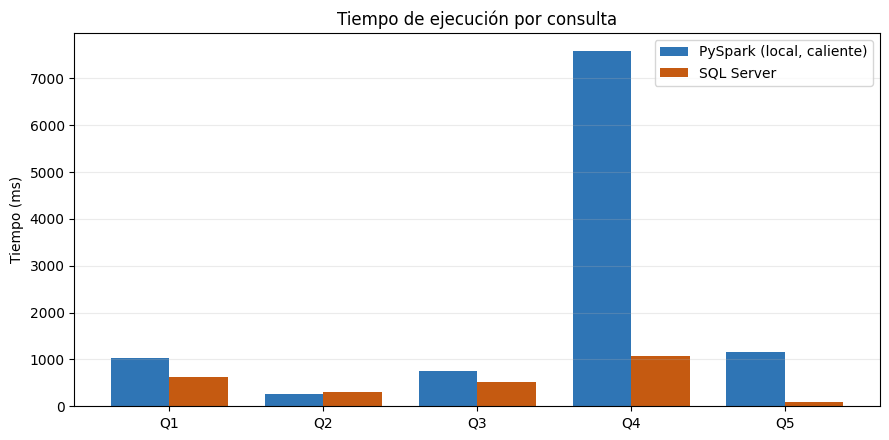

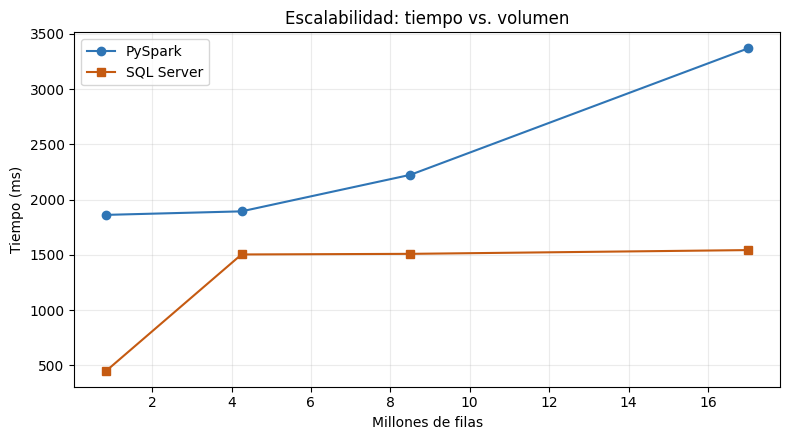

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = range(len(tabla)); w = 0.38
ax.bar([i - w/2 for i in x], tabla["Spark caliente (ms)"], w, label="PySpark (local, caliente)", color="#2F75B5")
if tabla["SQL Server (ms)"].notna().any():
    ax.bar([i + w/2 for i in x], tabla["SQL Server (ms)"].fillna(0), w, label="SQL Server", color="#C55A11")
ax.set_xticks(list(x)); ax.set_xticklabels(tabla["Consulta"]); ax.set_ylabel("Tiempo (ms)")
ax.set_title("Tiempo de ejecución por consulta"); ax.legend(); ax.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()

if df_escala is not None:
    df_escala["sqlserver_ms"] = df_escala["factor"].map(ESCALA_SQLSERVER_MS)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(df_escala["filas"]/1e6, df_escala["spark_ms"], marker="o", label="PySpark", color="#2F75B5")
    if df_escala["sqlserver_ms"].notna().any():
        ax.plot(df_escala["filas"]/1e6, df_escala["sqlserver_ms"], marker="s", label="SQL Server", color="#C55A11")
    ax.set_xlabel("Millones de filas"); ax.set_ylabel("Tiempo (ms)"); ax.set_title("Escalabilidad: tiempo vs. volumen")
    ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

In [22]:
# Lectura automática de resultados: genera frases con los datos medidos
print("=== LECTURA AUTOMÁTICA DE RESULTADOS ===")
for _, r in tabla.iterrows():
    if pd.notna(r["SQL Server (ms)"]):
        ganador = "SQL Server" if r["SQL Server (ms)"] < r["Spark caliente (ms)"] else "PySpark"
        print(f"{r['Consulta']}: SQL Server {r['SQL Server (ms)']:.0f} ms vs PySpark {r['Spark caliente (ms)']:.0f} ms "
              f"(fría {r['Spark fría (ms)']:.0f} ms) -> más rápido: {ganador}")

# Linealidad del escalado en Spark: si crece ~proporcional al volumen, la solución escala linealmente
if len(df_escala) > 1:
    base = df_escala.iloc[0]
    for _, r in df_escala.iloc[1:].iterrows():
        print(f"x{int(r.factor)}: el volumen crece x{r.factor} y el tiempo de Spark crece x{r.spark_ms/base.spark_ms:.1f}")

=== LECTURA AUTOMÁTICA DE RESULTADOS ===
Q1: SQL Server 620 ms vs PySpark 1021 ms (fría 4115 ms) -> más rápido: SQL Server
Q2: SQL Server 316 ms vs PySpark 253 ms (fría 814 ms) -> más rápido: PySpark
Q3: SQL Server 510 ms vs PySpark 751 ms (fría 1473 ms) -> más rápido: SQL Server
Q4: SQL Server 1068 ms vs PySpark 7594 ms (fría 15816 ms) -> más rápido: SQL Server
Q5: SQL Server 86 ms vs PySpark 1156 ms (fría 1598 ms) -> más rápido: SQL Server
x5: el volumen crece x5.0 y el tiempo de Spark crece x1.0
x10: el volumen crece x10.0 y el tiempo de Spark crece x1.2
x20: el volumen crece x20.0 y el tiempo de Spark crece x1.8


## 8. Análisis de eficiencia, escalabilidad y adecuación

### 8.1 Adecuación al volumen y naturaleza del dataset (las 4V)
| V | Evidencia del proyecto | Implicancia |
|---|---|---|
| **Volumen** | 850 366 filas × 24 campos (diabetes) + 290 469 / 374 083 / 931 763 filas (RN): ≈ 2,4 M de filas en total, de orden de cientos de MB, que caben en la memoria de un solo servidor | Por debajo del umbral donde un motor distribuido es imprescindible |
| **Velocidad** | Cargas por corte (`FECHA_CORTE` 202512), actualizaciones periódicas, procesamiento *batch* | No requiere *streaming* |
| **Variedad** | Tabular estructurado; el dataset RN tiene jerarquía prestación → diagnóstico → medicamento (ya modelada en MongoDB, Cap. IV) | Spark lee CSV/Parquet/JSON sin cambiar de motor |
| **Veracidad** | 73,59 % de nulos en campos de última atención; 19 + 2 registros eliminados; 22 casos de sexo ambiguo | Spark sirve para perfilado masivo y limpieza reproducible |

### 8.2 Eficiencia

El análisis de eficiencia se realizó mediante cinco consultas equivalentes implementadas en PySpark y SQL Server, considerando los tiempos de ejecución caliente para reducir la influencia de los costos iniciales.

Los resultados evidenciaron que SQL Server obtuvo menores tiempos en cuatro de las cinco consultas evaluadas: Q1 (619,5 ms), Q3 (510,0 ms), Q4 (1068,0 ms) y Q5 (86,5 ms). Por su parte, PySpark presentó un mejor rendimiento en Q2, con 252,7 ms frente a 315,5 ms de SQL Server.

La mayor diferencia se observó en Q5, correspondiente al filtrado por rango de fechas, donde SQL Server fue aproximadamente 13,4 veces más rápido. En Q4, que involucra la unión de tres tablas, SQL Server presentó un tiempo aproximadamente 7,1 veces menor que PySpark.

En PySpark, las ejecuciones frías fueron más lentas que las calientes en las cinco consultas. Este comportamiento puede relacionarse con costos iniciales de planificación, inicialización y preparación de tareas, además de posibles efectos de caché y lectura de datos.

El uso de Parquet favorece el procesamiento analítico mediante almacenamiento columnar y lectura selectiva de columnas. SQL Server, por su parte, dispone de mecanismos de optimización de consultas e índices que pueden favorecer determinadas operaciones.

En consecuencia, los resultados muestran que SQL Server fue más eficiente para la mayoría de las consultas evaluadas en este experimento, aunque las diferencias observadas también pueden estar influenciadas por el hardware, los formatos de almacenamiento y los planes de ejecución.
### 8.3 Escalabilidad

La evaluación de escalabilidad se realizó mediante cuatro factores de crecimiento (1×, 5×, 10× y 20×), utilizando una replicación lógica del conjunto de datos de diabetes, cuyo volumen inicial fue de 850 366 registros.

| Factor | Registros lógicos | PySpark (ms) | SQL Server (ms) |
|---|---:|---:|---:|
| 1× | 850 366 | 1861,7 | 452,5 |
| 5× | 4 251 830 | 1893,5 | 1503,5 |
| 10× | 8 503 660 | 2224,0 | 1509,0 |
| 20× | 17 007 320 | 3367,6 | 1543,0 |

En PySpark, el tiempo de ejecución aumentó aproximadamente 1,81 veces al multiplicar por 20 el volumen lógico de datos. Este comportamiento evidencia un crecimiento subproporcional del tiempo dentro de las condiciones experimentales evaluadas.

En SQL Server, el tiempo aumentó aproximadamente 3,41 veces entre los factores 1× y 20×. Sin embargo, se observó una estabilización relativa a partir del factor 5×, posiblemente relacionada con las optimizaciones del motor sobre la consulta utilizada.

Desde el punto de vista arquitectónico, SQL Server permite ampliar recursos principalmente mediante escalamiento vertical, mientras que Apache Spark está diseñado para distribuir el procesamiento entre múltiples nodos mediante escalamiento horizontal.

No obstante, la prueba de PySpark se ejecutó en Google Colab en modo local y no en un clúster distribuido. Por ello, los resultados permiten analizar el comportamiento de las consultas ante una expansión lógica de datos, pero no demuestran directamente la eficiencia del escalamiento horizontal.

Asimismo, las pruebas se realizaron en entornos diferentes y los optimizadores de ambos motores pueden procesar la replicación lógica de distintas maneras. En consecuencia, los resultados deben interpretarse como evidencia experimental limitada al escenario implementado.

### 8.4 Conclusión y recomendación

La evaluación experimental permitió comparar el rendimiento de PySpark y SQL Server mediante cinco consultas analíticas y cuatro escenarios de escalabilidad, utilizando los conjuntos de datos de diabetes y prestaciones de recién nacidos del proyecto DataSalud Perú.

**Rendimiento de las consultas.** SQL Server presentó menores tiempos de ejecución en cuatro de las cinco consultas evaluadas. En Q1 registró 619,5 ms frente a 1020,9 ms de PySpark (1,6 veces más rápido); en Q3 obtuvo 510,0 ms frente a 750,6 ms (1,5 veces); en Q4 alcanzó 1068,0 ms frente a 7594,3 ms (7,1 veces); y en Q5 registró 86,5 ms frente a 1156,2 ms (13,4 veces). La excepción fue Q2, donde PySpark obtuvo un mejor tiempo, con 252,7 ms frente a los 315,5 ms de SQL Server.

**Comportamiento de escalabilidad.** Al incrementar el volumen lógico de 850 366 a 17 007 320 registros (factores 1× a 20×), PySpark pasó de 1861,7 ms a 3367,6 ms, lo que representa un incremento aproximado de 1,81 veces en el tiempo para un volumen 20 veces mayor. SQL Server pasó de 452,5 ms a 1543,0 ms, equivalente a un incremento de 3,41 veces. No obstante, sus tiempos se mantuvieron relativamente estables entre los factores 5× y 20×, posiblemente debido a optimizaciones del motor sobre la replicación lógica de registros.

Estos resultados describen el comportamiento observado en los entornos evaluados, pero no permiten establecer una superioridad general de un motor sobre otro. La ejecución de PySpark se realizó en Google Colab en modo local, mientras que SQL Server se ejecutó en un equipo diferente. Además, las diferencias de almacenamiento, caché, planificación de consultas y optimización pueden influir en los tiempos registrados.

**Recomendación tecnológica.** Para el volumen actual del proyecto, SQL Server resulta adecuado como sistema principal de almacenamiento y consulta, especialmente por sus mecanismos de integridad transaccional, seguridad, auditoría y optimización mediante índices.

PySpark se recomienda como componente complementario para procesos analíticos, transformación de datos y futuras necesidades de procesamiento de mayores volúmenes. Su arquitectura permite distribuir tareas entre varios nodos cuando se dispone de un clúster, aunque esta capacidad no fue evaluada directamente en el experimento.

Por tanto, se propone mantener una arquitectura híbrida: SQL Server como sistema relacional principal, MongoDB para la representación documental de datos jerárquicos y PySpark como herramienta complementaria de procesamiento analítico.

**Limitaciones.** Las mediciones se realizaron en entornos de hardware diferentes, con mecanismos de caché y formatos de almacenamiento distintos. Asimismo, las pruebas de escalabilidad utilizaron replicación lógica y no una ampliación física de los conjuntos de datos. Para obtener una comparación más controlada, sería necesario igualar las condiciones de ejecución, verificar los planes de consulta y repetir las mediciones bajo un protocolo experimental uniforme.